# Which health programmes should be prioritized?

This chart ranks programmes by job postings per study place. Higher values indicate more observed job postings relative to the number of places. The three highest-ranked programmes are highlighted. The dashed line marks one posting per study place. This is an indicator for comparison, not proof of a workforce shortage.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

ROOT = Path.cwd()
if not (ROOT / "data/eval").exists():
    ROOT = ROOT.parent

ranks = pd.read_csv(ROOT / "data/eval/ranking_ranks.csv", index_col="programme")
plot_data = ranks.sort_values("postings_per_place", ascending=True)
colors = ["#D97941" if rank <= 3 else "#B8C2CC" for rank in plot_data["rank_method"]]

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

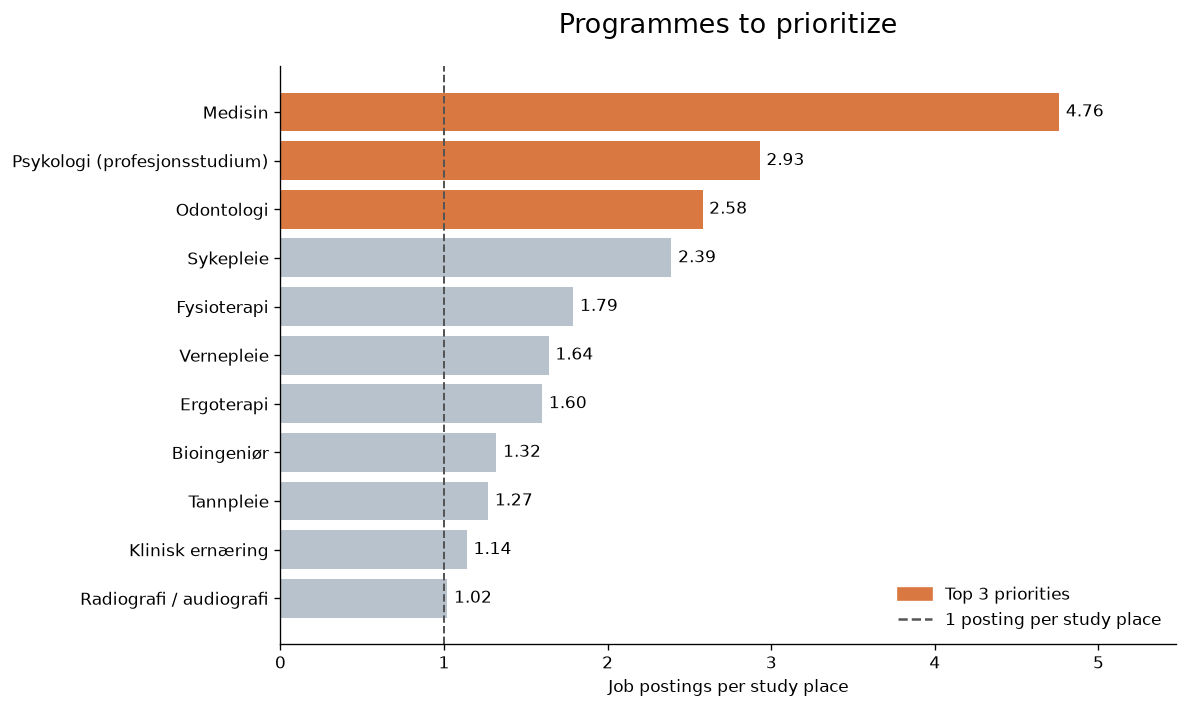

In [2]:
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    plot_data.index,
    plot_data["postings_per_place"],
    color=colors,
)

ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_xlim(0, plot_data["postings_per_place"].max() * 1.15)
ax.axvline(1, color="#555555", linestyle="--", linewidth=1.2)
ax.set_title("Programmes to prioritize", fontsize=16, pad=20)
ax.set_xlabel("Job postings per study place")
ax.set_ylabel("")
ax.legend(
    handles=[
        Patch(color="#D97941", label="Top 3 priorities"),
        Line2D([0], [0], color="#555555", linestyle="--", label="1 posting per study place"),
    ],
    loc="lower right",
    frameon=False,
)

fig.tight_layout()
fig.savefig(FIGURES / "programmes_to_prioritize.png", bbox_inches="tight", dpi=200)
plt.show()

## Skills employers ask for in the top 3

For each of the three highest-ranked programmes, the five skills that ESCO lists for the occupation (essential or optional) and that the postings ask for most often. Skills come from the LLM method (`skills_by_programme_llm.csv`). The share is of current postings, which still have their text, so Psykologi (71) and Odontologi (47) rest on few postings. General skills not in the ESCO profile, such as *norsk* and *kommunikasjon*, are left out because they are top for every programme.

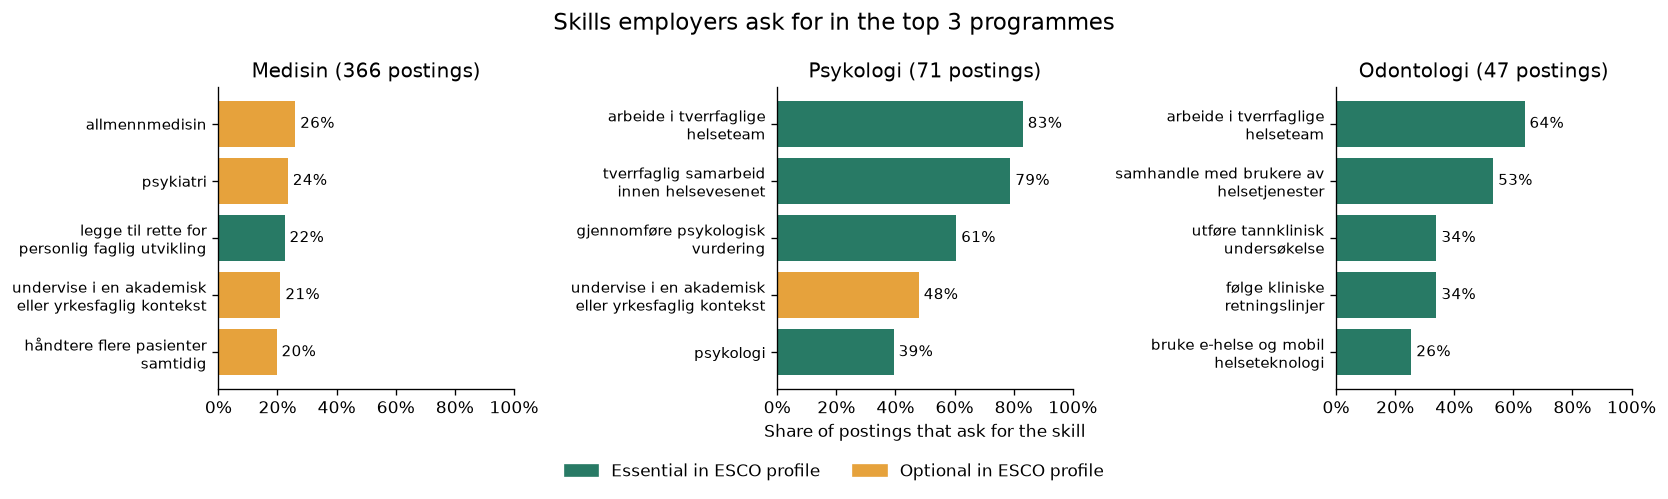

In [3]:
import textwrap
from matplotlib.ticker import PercentFormatter

skills = pd.read_csv(ROOT / "data/processed/skills_by_programme_llm.csv")
gap = pd.read_csv(ROOT / "data/processed/gap_by_programme.csv", index_col="programme")
top3 = gap.sort_values("rank").index[:3]

skill_colors = {"essential": "#287A65", "optional": "#E6A23C"}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for ax, programme in zip(axes, top3):
    top = (
        skills[(skills["programme"] == programme) & (skills["esco_relation"] != "none")]
        .nlargest(5, "share_postings")
        .sort_values("share_postings")
    )
    labels = [textwrap.fill(s, 26) for s in top["skill"]]
    bars = ax.barh(labels, top["share_postings"], color=top["esco_relation"].map(skill_colors))
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in top["share_postings"]], padding=3, fontsize=9)
    name = programme.replace(" (profesjonsstudium)", "")
    ax.set_title(f"{name} ({gap.loc[programme, 'n_snapshot']} postings)")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlim(0, 1)
    ax.tick_params(axis="y", labelsize=9)

axes[1].set_xlabel("Share of postings that ask for the skill")
fig.legend(
    handles=[
        Patch(color=skill_colors["essential"], label="Essential in ESCO profile"),
        Patch(color=skill_colors["optional"], label="Optional in ESCO profile"),
    ],
    loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False,
)
fig.suptitle("Skills employers ask for in the top 3 programmes", fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES / "top3_skills.png", bbox_inches="tight", dpi=200)
plt.show()